In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("car_done.csv")
df

,Unnamed: 0,Manufacturer,Model,Sales_in_thousands,four_year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
0,0,Acura,Integra,16.919,16.360,Passenger,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2/2/2012,58.280150
1,1,Acura,TL,39.384,19.875,Passenger,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,6/3/2011,91.370778
2,2,Acura,CL,14.114,18.225,Passenger,NaN,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,1/4/2012,NaN
3,3,Acura,RL,8.588,29.725,Passenger,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,3/10/2011,91.389779
4,4,Audi,A4,20.397,22.255,Passenger,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,10/8/2011,62.777639
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,152,Volvo,V40,3.545,NaN,Passenger,24.40,1.9,160.0,100.5,67.6,176.6,3.042,15.8,25.0,9/21/2011,66.498812
153,153,Volvo,S70,15.245,NaN,Passenger,27.50,2.4,168.0,104.9,69.3,185.9,3.208,17.9,25.0,11/24/2012,70.654495
154,154,Volvo,V70,17.531,NaN,Passenger,28.80,2.4,168.0,104.9,69.3,186.2,3.259,17.9,25.0,6/25/2011,71.155978
155,155,Volvo,C70,3.493,NaN,Passenger,45.50,2.3,236.0,104.9,71.5,185.7,3.601,18.5,23.0,4/26/2011,101.623357


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              157 non-null    int64  
 1   Manufacturer            157 non-null    object 
 2   Model                   157 non-null    object 
 3   Sales_in_thousands      157 non-null    float64
 4   four_year_resale_value  121 non-null    float64
 5   Vehicle_type            157 non-null    object 
 6   Price_in_thousands      155 non-null    float64
 7   Engine_size             156 non-null    float64
 8   Horsepower              156 non-null    float64
 9   Wheelbase               156 non-null    float64
 10  Width                   156 non-null    float64
 11  Length                  156 non-null    float64
 12  Curb_weight             155 non-null    float64
 13  Fuel_capacity           156 non-null    float64
 14  Fuel_efficiency         154 non-null    fl

In [4]:
df.columns

Index(['Unnamed: 0', 'Manufacturer', 'Model', 'Sales_in_thousands',
       'four_year_resale_value', 'Vehicle_type', 'Price_in_thousands',
       'Engine_size', 'Horsepower', 'Wheelbase', 'Width', 'Length',
       'Curb_weight', 'Fuel_capacity', 'Fuel_efficiency', 'Latest_Launch',
       'Power_perf_factor'],
      dtype='object')

In [5]:
df.isnull() # gives the true and false column wise
df.isnull().sum()  # give the number of null values

Unnamed: 0                 0
Manufacturer               0
Model                      0
Sales_in_thousands         0
four_year_resale_value    36
Vehicle_type               0
Price_in_thousands         2
Engine_size                1
Horsepower                 1
Wheelbase                  1
Width                      1
Length                     1
Curb_weight                2
Fuel_capacity              1
Fuel_efficiency            3
Latest_Launch              0
Power_perf_factor          2
dtype: int64

In [6]:
df["four_year_resale_value"].median()

14.18

In [7]:
df["four_year_resale_value"].fillna(value=df["four_year_resale_value"].median())

0      16.360
1      19.875
2      18.225
3      29.725
4      22.255
        ...  
152    14.180
153    14.180
154    14.180
155    14.180
156    14.180
Name: four_year_resale_value, Length: 157, dtype: float64

In [8]:
df["four_year_resale_value"].fillna(value=(df["four_year_resale_value"].median()))
# replace null values to median value

0      16.360
1      19.875
2      18.225
3      29.725
4      22.255
        ...  
152    14.180
153    14.180
154    14.180
155    14.180
156    14.180
Name: four_year_resale_value, Length: 157, dtype: float64

In [9]:
df["four_year_resale_value"].fillna(value=(df["four_year_resale_value"].median()),inplace=True)
# make changes in original instead of giving only tempary change 

In [10]:
df["four_year_resale_value"].isnull().sum()

np.int64(0)

In [11]:
for i in df.select_dtypes([int,float]):
    df[i]=df[i].fillna(value=df[i].median())
# very very important 

In [12]:
# EDA

In [13]:
# df["Sales_in_thousands"].unique()
# give all unique values


In [14]:
df.nunique()

Unnamed: 0                157
Manufacturer               30
Model                     156
Sales_in_thousands        157
four_year_resale_value    117
Vehicle_type                2
Price_in_thousands        152
Engine_size                31
Horsepower                 67
Wheelbase                  88
Width                      79
Length                    128
Curb_weight               147
Fuel_capacity              55
Fuel_efficiency            20
Latest_Launch             130
Power_perf_factor         154
dtype: int64

In [15]:
for i in df:
    if df[i].nunique()<50:
        print(i)
        print(df[i].unique)
        print("**********************")

Manufacturer
<bound method Series.unique of 0      Acura
1      Acura
2      Acura
3      Acura
4       Audi
       ...  
152    Volvo
153    Volvo
154    Volvo
155    Volvo
156    Volvo
Name: Manufacturer, Length: 157, dtype: object>
**********************
Vehicle_type
<bound method Series.unique of 0      Passenger
1      Passenger
2      Passenger
3      Passenger
4      Passenger
         ...    
152    Passenger
153    Passenger
154    Passenger
155    Passenger
156    Passenger
Name: Vehicle_type, Length: 157, dtype: object>
**********************
Engine_size
<bound method Series.unique of 0      1.8
1      3.2
2      3.2
3      3.5
4      1.8
      ... 
152    1.9
153    2.4
154    2.4
155    2.3
156    2.9
Name: Engine_size, Length: 157, dtype: float64>
**********************
Fuel_efficiency
<bound method Series.unique of 0      28.0
1      25.0
2      26.0
3      22.0
4      27.0
       ... 
152    25.0
153    25.0
154    25.0
155    23.0
156    24.0
Name: Fuel_efficiency, Len

In [16]:
for i in df:
    if df[i].nunique()<50:
        print(df[i].value_counts())
        print("********************")

Manufacturer
Ford          11
Dodge         11
Chevrolet      9
Mercedes-B     9
Toyota         9
Chrysler       7
Mitsubishi     7
Nissan         7
Mercury        6
Oldsmobile     6
Lexus          6
Pontiac        6
Volvo          6
Volkswagen     6
Cadillac       5
Honda          5
Saturn         5
Plymouth       4
Buick          4
Acura          4
Audi           3
BMW            3
Lincoln        3
Porsche        3
Jeep           3
Hyundai        3
Saab           2
Subaru         2
Jaguar         1
Infiniti       1
Name: count, dtype: int64
********************
Vehicle_type
Passenger    116
Car           41
Name: count, dtype: int64
********************
Engine_size
2.0    17
3.0    15
2.5    11
2.4    11
4.6     9
3.5     8
3.8     8
1.8     8
4.0     7
3.4     7
3.2     6
2.3     6
1.9     5
3.3     5
2.7     4
2.2     4
3.1     4
2.8     3
5.7     2
5.0     2
4.7     2
5.2     2
3.9     2
4.3     2
4.2     1
1.0     1
8.0     1
1.6     1
1.5     1
5.4     1
2.9     1
Name: count, d

In [17]:
import pandas as pd

In [18]:
df=pd.read_csv("car_done.csv")
df

,Unnamed: 0,Manufacturer,Model,Sales_in_thousands,four_year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
0,0,Acura,Integra,16.919,16.360,Passenger,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2/2/2012,58.280150
1,1,Acura,TL,39.384,19.875,Passenger,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,6/3/2011,91.370778
2,2,Acura,CL,14.114,18.225,Passenger,NaN,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,1/4/2012,NaN
3,3,Acura,RL,8.588,29.725,Passenger,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,3/10/2011,91.389779
4,4,Audi,A4,20.397,22.255,Passenger,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,10/8/2011,62.777639
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,152,Volvo,V40,3.545,NaN,Passenger,24.40,1.9,160.0,100.5,67.6,176.6,3.042,15.8,25.0,9/21/2011,66.498812
153,153,Volvo,S70,15.245,NaN,Passenger,27.50,2.4,168.0,104.9,69.3,185.9,3.208,17.9,25.0,11/24/2012,70.654495
154,154,Volvo,V70,17.531,NaN,Passenger,28.80,2.4,168.0,104.9,69.3,186.2,3.259,17.9,25.0,6/25/2011,71.155978
155,155,Volvo,C70,3.493,NaN,Passenger,45.50,2.3,236.0,104.9,71.5,185.7,3.601,18.5,23.0,4/26/2011,101.623357


In [19]:
df["four_year_resale_value"].isnull().sum()

np.int64(36)

In [20]:
df["four_year_resale_value"].fillna(value=df["four_year_resale_value"].median(),inplace=True)

In [21]:
df["four_year_resale_value"].isnull().sum()

np.int64(0)

In [22]:
for i in df.select_dtypes([int,float]):
    df[i]=df["four_year_resale_value"].fillna(value=df["four_year_resale_value"].median())
    print(i)
    print(df[i])

Unnamed: 0
0      16.360
1      19.875
2      18.225
3      29.725
4      22.255
        ...  
152    14.180
153    14.180
154    14.180
155    14.180
156    14.180
Name: Unnamed: 0, Length: 157, dtype: float64
Sales_in_thousands
0      16.360
1      19.875
2      18.225
3      29.725
4      22.255
        ...  
152    14.180
153    14.180
154    14.180
155    14.180
156    14.180
Name: Sales_in_thousands, Length: 157, dtype: float64
four_year_resale_value
0      16.360
1      19.875
2      18.225
3      29.725
4      22.255
        ...  
152    14.180
153    14.180
154    14.180
155    14.180
156    14.180
Name: four_year_resale_value, Length: 157, dtype: float64
Price_in_thousands
0      16.360
1      19.875
2      18.225
3      29.725
4      22.255
        ...  
152    14.180
153    14.180
154    14.180
155    14.180
156    14.180
Name: Price_in_thousands, Length: 157, dtype: float64
Engine_size
0      16.360
1      19.875
2      18.225
3      29.725
4      22.255
        ...  
152 

In [23]:
df.select_dtypes([object])

,Manufacturer,Model,Vehicle_type,Latest_Launch
0,Acura,Integra,Passenger,2/2/2012
1,Acura,TL,Passenger,6/3/2011
2,Acura,CL,Passenger,1/4/2012
3,Acura,RL,Passenger,3/10/2011
4,Audi,A4,Passenger,10/8/2011
...,...,...,...,...
152,Volvo,V40,Passenger,9/21/2011
153,Volvo,S70,Passenger,11/24/2012
154,Volvo,V70,Passenger,6/25/2011
155,Volvo,C70,Passenger,4/26/2011


In [24]:
df["Vehicle_type"].value_counts()

Vehicle_type
Passenger    116
Car           41
Name: count, dtype: int64

In [25]:
df=df.drop(columns=['Manufacturer','Model','Latest_Launch'])

In [26]:
df=df.drop(columns=["Unnamed: 0"])

In [27]:
df

,Sales_in_thousands,four_year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
0,16.360,16.360,Passenger,16.360,16.360,16.360,16.360,16.360,16.360,16.360,16.360,16.360,16.360
1,19.875,19.875,Passenger,19.875,19.875,19.875,19.875,19.875,19.875,19.875,19.875,19.875,19.875
2,18.225,18.225,Passenger,18.225,18.225,18.225,18.225,18.225,18.225,18.225,18.225,18.225,18.225
3,29.725,29.725,Passenger,29.725,29.725,29.725,29.725,29.725,29.725,29.725,29.725,29.725,29.725
4,22.255,22.255,Passenger,22.255,22.255,22.255,22.255,22.255,22.255,22.255,22.255,22.255,22.255
...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,14.180,14.180,Passenger,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180
153,14.180,14.180,Passenger,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180
154,14.180,14.180,Passenger,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180
155,14.180,14.180,Passenger,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180


In [28]:
df["Vehicle_type"]=np.where(df["Vehicle_type"]=="Car",1,0)

In [29]:
df["Vehicle_type"].value_counts()

Vehicle_type
0    116
1     41
Name: count, dtype: int64

In [30]:

#  remove all outlayers 
#  to remove outliers we use ior method
# iqr=inter quartile range
# IQR=q3-q1
# lowerfence=q1-(1.5*IQR)
# upper fence =q3=(1.5*IQR)


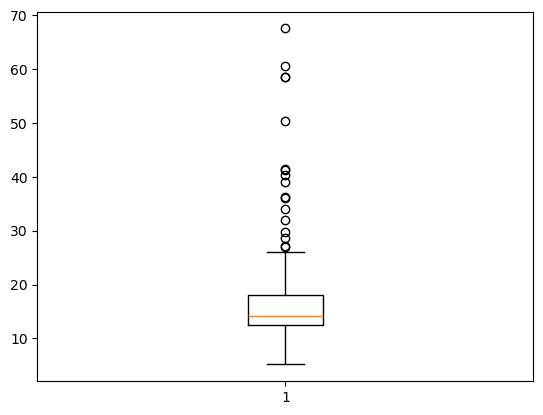

In [31]:
# boxplot use maximum 5 number summary  
plt.boxplot(df["Sales_in_thousands"])
plt.show()

In [32]:
q1=df["Sales_in_thousands"].quantile(0.25)
q3=df["Sales_in_thousands"].quantile(0.75)
iqr=q3-q1
lf=q1-(1.5*iqr)
uf=q3+(1.5*iqr)
print(lf, uf)

4.152499999999998 26.532500000000002


In [33]:
df["Sales_in_thousands"]=np.where(df["Sales_in_thousands"]>148.719,148.719,df["Sales_in_thousands"])

{'whiskers': [<matplotlib.lines.Line2D at 0x20156648910>,
 'caps': [<matplotlib.lines.Line2D at 0x20156648b90>,
 'boxes': [<matplotlib.lines.Line2D at 0x201566487d0>],
 'medians': [<matplotlib.lines.Line2D at 0x20156648e10>],
 'fliers': [<matplotlib.lines.Line2D at 0x20156648f50>],
 'means': []}

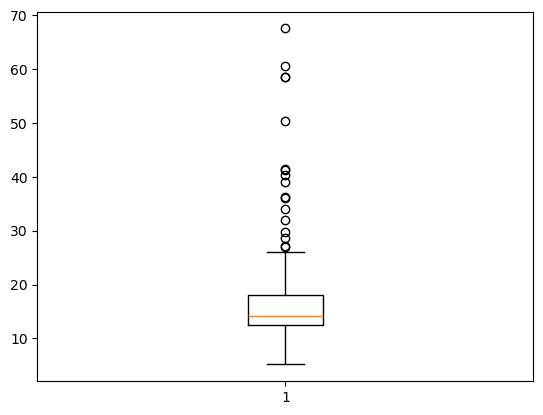

In [34]:
plt.boxplot(df["Sales_in_thousands"])

In [35]:
for i in df.select_dtypes([int,float]):
    q1=df[i].quantile(0.25)
    q3=df[i].quantile(0.75)
    iqr=q3-q1
    lf=q1-(1.5*iqr)
    uf=q3+(1.5*iqr)
    df[i]=np.where(df[i]<lf,lf,df[i])
    df[i]=np.where(df[i]>uf,uf,df[i])

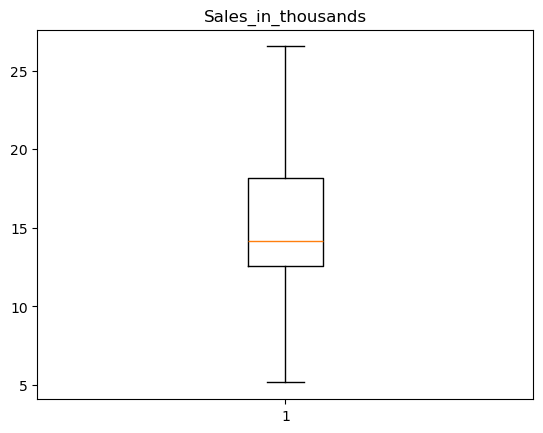

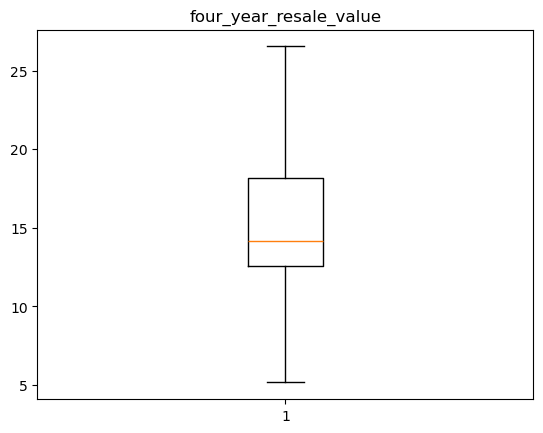

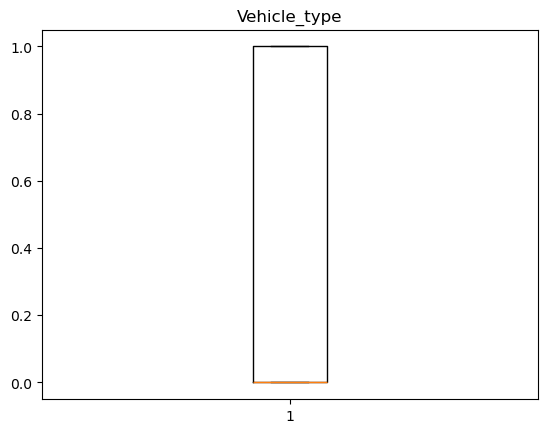

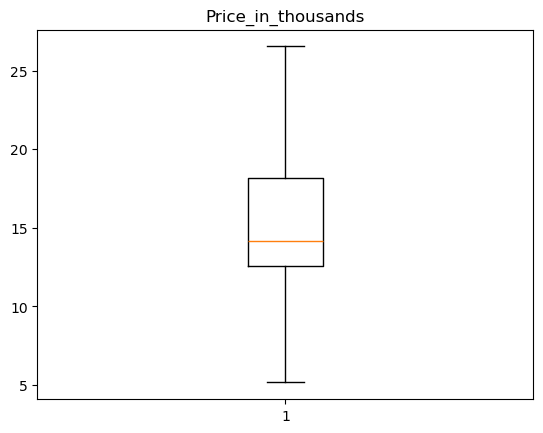

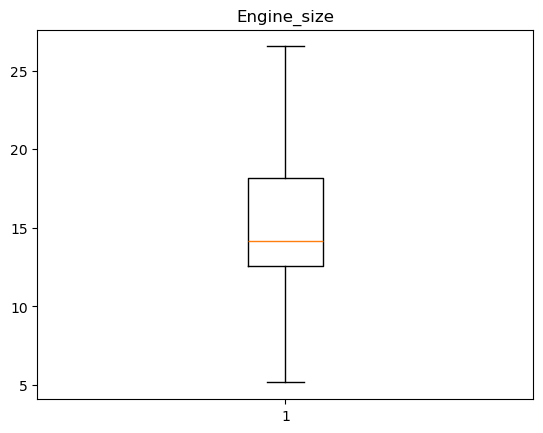

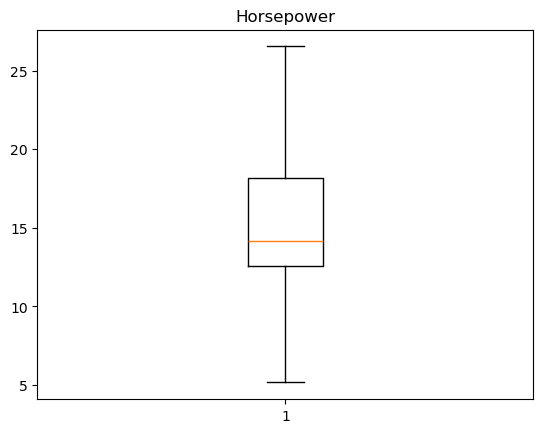

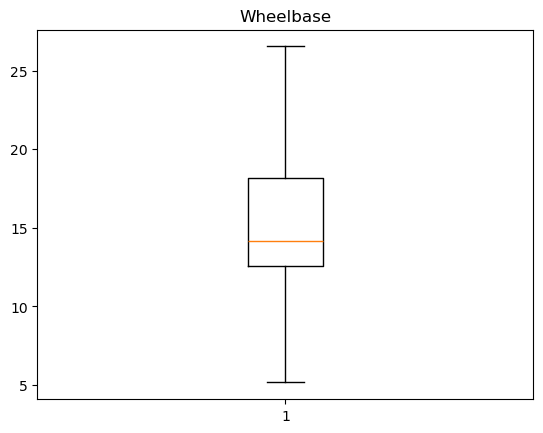

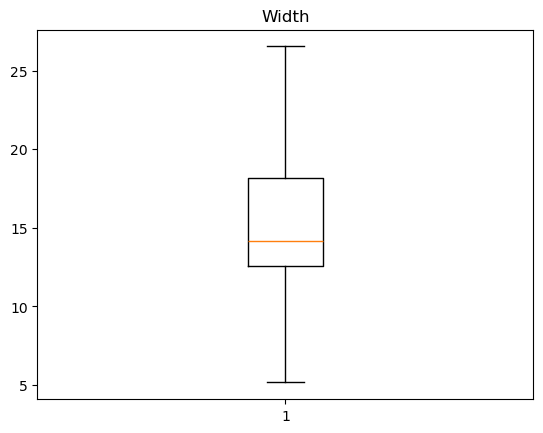

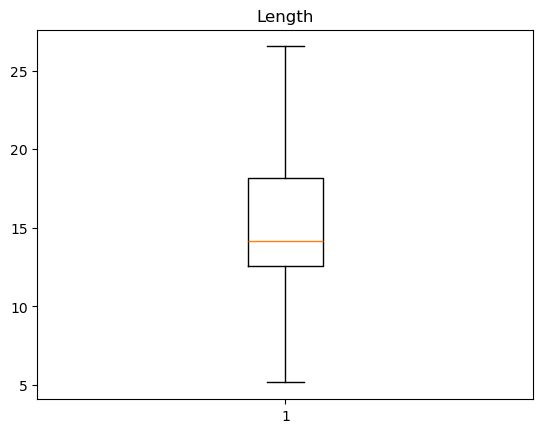

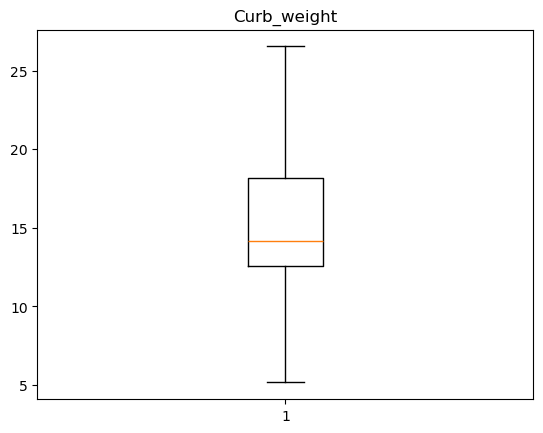

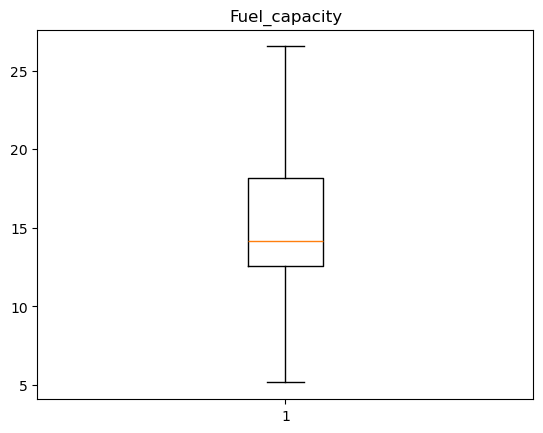

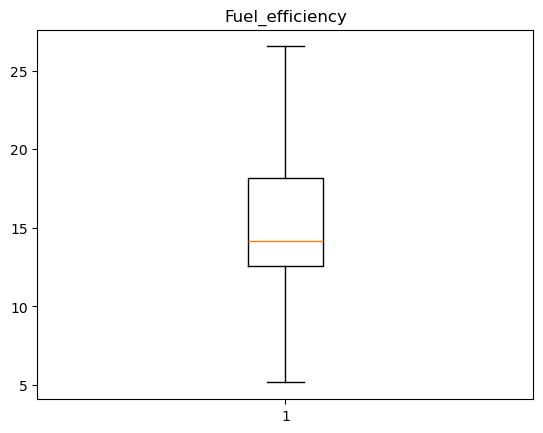

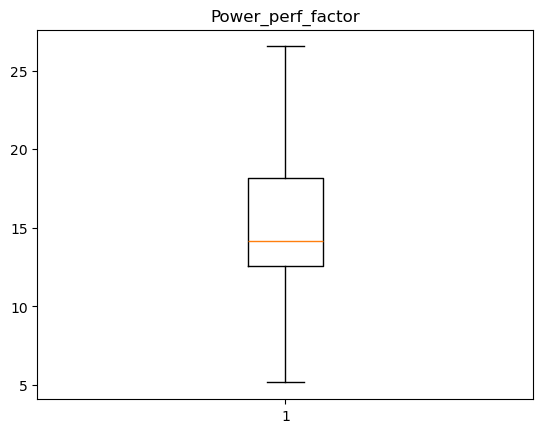

In [36]:
for i in df.select_dtypes([int,float]):
    plt.boxplot(df[i])
    plt.title(i)
    plt.show()

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Sales_in_thousands      157 non-null    float64
 1   four_year_resale_value  157 non-null    float64
 2   Vehicle_type            157 non-null    float64
 3   Price_in_thousands      157 non-null    float64
 4   Engine_size             157 non-null    float64
 5   Horsepower              157 non-null    float64
 6   Wheelbase               157 non-null    float64
 7   Width                   157 non-null    float64
 8   Length                  157 non-null    float64
 9   Curb_weight             157 non-null    float64
 10  Fuel_capacity           157 non-null    float64
 11  Fuel_efficiency         157 non-null    float64
 12  Power_perf_factor       157 non-null    float64
dtypes: float64(13)
memory usage: 16.1 KB


In [38]:
y=df["Sales_in_thousands"];
x=df.drop(columns=["Sales_in_thousands"]);

In [39]:
# print(df["Sales_in_thousands"]) will give error

In [40]:
from sklearn.model_selection import train_test_split

In [41]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=88)

In [42]:
x_train

,four_year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Power_perf_factor
55,7.850,1.0,7.850,7.850,7.850,7.850,7.850,7.850,7.850,7.850,7.850,7.850
104,15.380,1.0,15.380,15.380,15.380,15.380,15.380,15.380,15.380,15.380,15.380,15.380
36,12.545,0.0,12.545,12.545,12.545,12.545,12.545,12.545,12.545,12.545,12.545,12.545
109,14.180,0.0,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180
98,14.180,0.0,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180
...,...,...,...,...,...,...,...,...,...,...,...,...
62,5.860,0.0,5.860,5.860,5.860,5.860,5.860,5.860,5.860,5.860,5.860,5.860
101,8.450,0.0,8.450,8.450,8.450,8.450,8.450,8.450,8.450,8.450,8.450,8.450
148,16.575,0.0,16.575,16.575,16.575,16.575,16.575,16.575,16.575,16.575,16.575,16.575
106,14.180,1.0,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180,14.180


In [43]:
y_train

55      7.850
104    15.380
36     12.545
109    14.180
98     14.180
        ...  
62      5.860
101     8.450
148    16.575
106    14.180
32     17.325
Name: Sales_in_thousands, Length: 109, dtype: float64

In [44]:
from sklearn.linear_model import LinearRegression

In [45]:
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [46]:
model.score(x_train,y_train)

1.0

In [47]:
from sklearn.metrics import mean_squared_error

In [48]:
actual = y_train
pre = model.predict(x_train)

In [49]:
mean_squared_error(actual,pre)

1.6305537793237977e-29

In [50]:
print("RMSE",np.sqrt(mean_squared_error(actual,pre)))

RMSE 4.038011613806723e-15


<Axes: xlabel='Sales_in_thousands', ylabel='Density'>

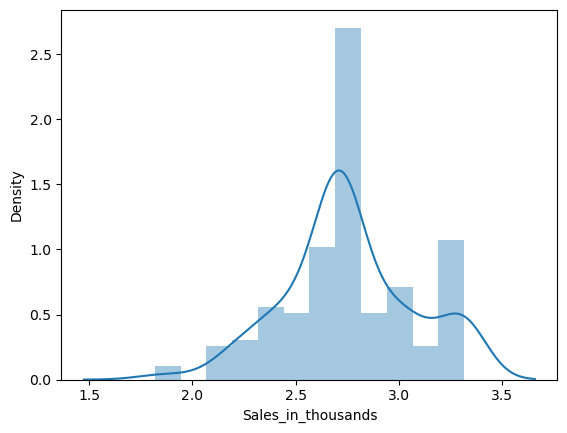

In [51]:
import seaborn as sns
sns.distplot(np.log1p(df["Sales_in_thousands"]))

In [ ]:
import pandas as pd
import numpy as np
data=np.array(input().split(),dtype=float)

In [ ]:
df=pd.DataFrame(data)
print(round(df[0].mean(),2))
print(round(df[0].median(),2))
print(round(df[0].max()-df[0].min(),2))
print(round(df[0].var(),2))
print(round(df[0].std(),2))


In [ ]:
data1=np.array(input().split(),dtype=float)
df=pd.DataFrame(data1)
print(round(df[0].mean(),2))

In [ ]:
data2=np.array(input().split(),dtype=float)
df=pd.DataFrame(data2)
avg=round(df[0].mean(),2)
print("avg is",avg)
count=0
for i in data2:
    if i>avg:
        print(i)
        count+=1
print("total no greater than mean is",count)

In [ ]:
li=np.array(input().split(),dtype=float)
df=pd.DataFrame(li)
q1=df[0].quantile(0.25)
q3=df[0].quantile(0.75)
iqr=q3-q1
for i in li:
    if i>q1 and i<q3:
        print(i)
print(q1)
print(q3)

In [ ]:
li=np.array(input().split(),dtype=float)
df=pd.DataFrame(li)
q1=df[0].quantile(0.25)
q3=df[0].quantile(0.75)